In [33]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
import seaborn as sns


In [26]:
iris_df = load_iris(as_frame=True)
df = iris_df.frame
dfnew = pd.DataFrame()

In [27]:
for cols in iris_df.feature_names:
    dfnew[cols] = pd.cut(df[cols],bins=10,labels=False)
pmfs = {}
rows = len(dfnew)
for cols in iris_df.feature_names:
    counts = dfnew[cols].value_counts().reindex(range(10),fill_value=0)
    pmfarr = counts.to_numpy()/ rows
    pmfs[cols] = pmfarr

pmfsum = np.sum(pmfs[iris_df.feature_names[0]])
print(pmfsum)

1.0


In [ ]:
def entropy(p):
    p = np.array(p, dtype=np.float64)
    nonzero_p = p[p > 0]
    return -np.sum(nonzero_p * np.log2(nonzero_p))
def joint_entropy(p_xy):
    p_xy = np.array(p_xy, dtype=np.float64)
    nonzero_p = p_xy[p_xy > 0]
    return -np.sum(nonzero_p * np.log2(nonzero_p))
def mutual_information(x, y):
    x = np.array(x, dtype=np.int64)
    y = np.array(y, dtype=np.int64)
    n_samples = len(x)
    _, counts_x = np.unique(x, return_counts=True)
    _, counts_y = np.unique(y, return_counts=True)
    p_x = counts_x / n_samples
    p_y = counts_y / n_samples
    states_x = np.max(x) + 1
    states_y = np.max(y) + 1
    joint_counts = np.zeros((states_x, states_y), dtype=np.float64)
    for xi, yi in zip(x, y):
        joint_counts[xi, yi] += 1
    p_xy = joint_counts / n_samples
    
    h_x = entropy(p_x)
    h_y = entropy(p_y)
    h_xy = joint_entropy(p_xy)
    
    return h_x + h_y - h_xy


In [32]:
n = dfnew.shape[1] 
features = dfnew.columns.tolist()
M = np.zeros((n,n))
for i in range(n):
    for j in range(n):
        M[i,j] = mutual_information(dfnew.iloc[:,i].values,dfnew.iloc[:,j].values)
Mnew = pd.DataFrame(M,index=features,columns=features)
print(Mnew.values)


[[3.11888483 0.68935947 1.29667209 1.06365665]
 [0.68935947 2.7733349  0.70178823 0.87881258]
 [1.29667209 0.70178823 2.84598337 1.57275009]
 [1.06365665 0.87881258 1.57275009 2.93966977]]


<AxesSubplot:>

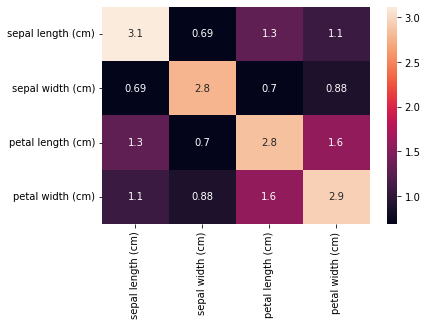

In [35]:
sns.heatmap(Mnew,annot=True)

In [39]:
pairs = Mnew.unstack().reset_index()
pairs.columns = ['Feature_A', 'Feature_B', 'MI_Value']
pairs = pairs[pairs['Feature_A'] != pairs['Feature_B']]
highest_pair = pairs.loc[pairs['MI_Value'].idxmax()]
print(f"Highest non-diagonal element: {highest_pair['MI_Value']:.4f}")
print(f"Features: {highest_pair['Feature_A']} and {highest_pair['Feature_B']}")


Highest non-diagonal element: 1.5728
Features: petal length (cm) and petal width (cm)
